 # Migration records data metrics

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from tqdm.cli import tqdm

from sys import path as sys_path
project_root = Path.cwd().parent.parent
if project_root not in sys_path:
    sys_path.append(str(project_root))
data_dir = project_root/"data/"
outputs_dir = project_root/"outputs/"

event_counts = Counter()
duplicate_pages = Counter()
duplicate_pages_per_parish = Counter()
pages_per_year = Counter()
duplicate_pages_per_year = Counter()
direction_counts = Counter()
duplicate_direction_counts = Counter()
toponym_counter = Counter()
pages_per_parish = Counter()
book_pages_counter = Counter()

# Track unique pages and their metadata
page_metadata = {}

with open(data_dir/"json/pl_id_to_pl.json", "r") as fp:
    p_id_to_p_name = json.load(fp)

p_id_to_p_name = {
    int(p_id): p_name
    for p_id, p_name in p_id_to_p_name.items()
}

 ## Process JSONL files

In [2]:
def extract_toponyms(toponyms_list):
    """Extract valid toponyms from a record."""
    return [
        item[1] for item in toponyms_list
        if len(item) >= 2 and item[1] and item[1] != "unknown"
    ]

migration_data_directory = Path(outputs_dir/"json/migration_jsonls/2-final")
files = list(migration_data_directory.glob("*_migration_events.jsonl"))

for file in tqdm(files):
    parish_id = int(file.stem.split("_")[0])
    with open(file, "r", encoding="utf-8") as f:
        for line in f:
            record = json.loads(line)
            event_counts[parish_id] += 1

            page_key = (record["book"], record["page_n"], record["side"])

            if page_key not in page_metadata:
                year_bucket = (record["year_prediction"] // 5) * 5
                is_dup = record["duplicate"]
                direction = record["in/out"]

                page_metadata[page_key] = {
                    "parish_id": parish_id,
                    "book": record["book"],
                    "is_duplicate": is_dup,
                    "direction": direction,
                    "year_bucket": year_bucket,
                }

                # All per-page counts — inside the page_key check to avoid
                # counting the same page multiple times (once per row)
                pages_per_parish[parish_id] += 1
                book_pages_counter[record["book"]] += 1
                direction_counts[direction] += 1
                pages_per_year[year_bucket] += 1

                if is_dup:
                    duplicate_pages[record["book"]] += 1
                    duplicate_pages_per_parish[parish_id] += 1
                    duplicate_direction_counts[direction] += 1
                    duplicate_pages_per_year[year_bucket] += 1

            # Toponyms are per event, not per page
            toponym_counter.update(extract_toponyms(record["possibly_related_toponyms"]))

100%|██████████| 468/468 [00:46<00:00, 10.10it/s]


 ## Convert counters to DataFrames

In [3]:
parish_event_counts = pd.DataFrame(
    event_counts.items(), columns=["parish_id", "event_count"]
).sort_values("event_count", ascending=False)
parish_event_counts["parish_name"] = parish_event_counts["parish_id"].map(p_id_to_p_name)

duplicate_pages_df = pd.DataFrame(
    duplicate_pages.items(), columns=["book", "duplicate_count"]
).sort_values("duplicate_count", ascending=False)

duplicate_pages_per_parish_df = pd.DataFrame(
    duplicate_pages_per_parish.items(),
    columns=["parish_id", "duplicate_count"],
).sort_values("duplicate_count", ascending=False)
duplicate_pages_per_parish_df["parish_name"] = duplicate_pages_per_parish_df["parish_id"].map(p_id_to_p_name)

pages_yearly = pd.DataFrame(
    {"year_bucket": list(pages_per_year.keys()), "total_pages": list(pages_per_year.values())}
).sort_values("year_bucket")

duplicate_pages_yearly = pd.DataFrame(
    {"year_bucket": list(duplicate_pages_per_year.keys()), "duplicate_pages": list(duplicate_pages_per_year.values())}
).sort_values("year_bucket")

direction_data = pd.DataFrame({
    "direction": list(direction_counts.keys()),
    "total_pages": list(direction_counts.values()),
    "duplicate_pages": [duplicate_direction_counts.get(d, 0) for d in direction_counts.keys()],
})
direction_data["non_duplicate_pages"] = (
    direction_data["total_pages"] - direction_data["duplicate_pages"]
)

toponym_df = pd.DataFrame(
    toponym_counter.most_common(25), columns=["toponym", "count"]
)

pages_per_parish_df = pd.DataFrame(
    pages_per_parish.items(), columns=["parish_id", "page_count"]
).sort_values("page_count", ascending=False)
pages_per_parish_df["parish_name"] = pages_per_parish_df["parish_id"].map(p_id_to_p_name)

book_pages_df = pd.DataFrame(
    book_pages_counter.items(), columns=["book", "page_count"]
).sort_values("page_count", ascending=False)

 ## Summary

In [4]:
total_pages = len(page_metadata)
print(f"Total events: {sum(event_counts.values())}")
print(f"Total unique pages: {total_pages}")
print(f"Total duplicate pages: {sum(duplicate_pages.values())}")
print(f"Unique parishes: {len(event_counts)}")
print(f"Unique books: {len(book_pages_counter)}")

Total events: 6723143
Total unique pages: 292773
Total duplicate pages: 31388
Unique parishes: 468
Unique books: 2763


 ## Books

 ### Top 25 books with most pages

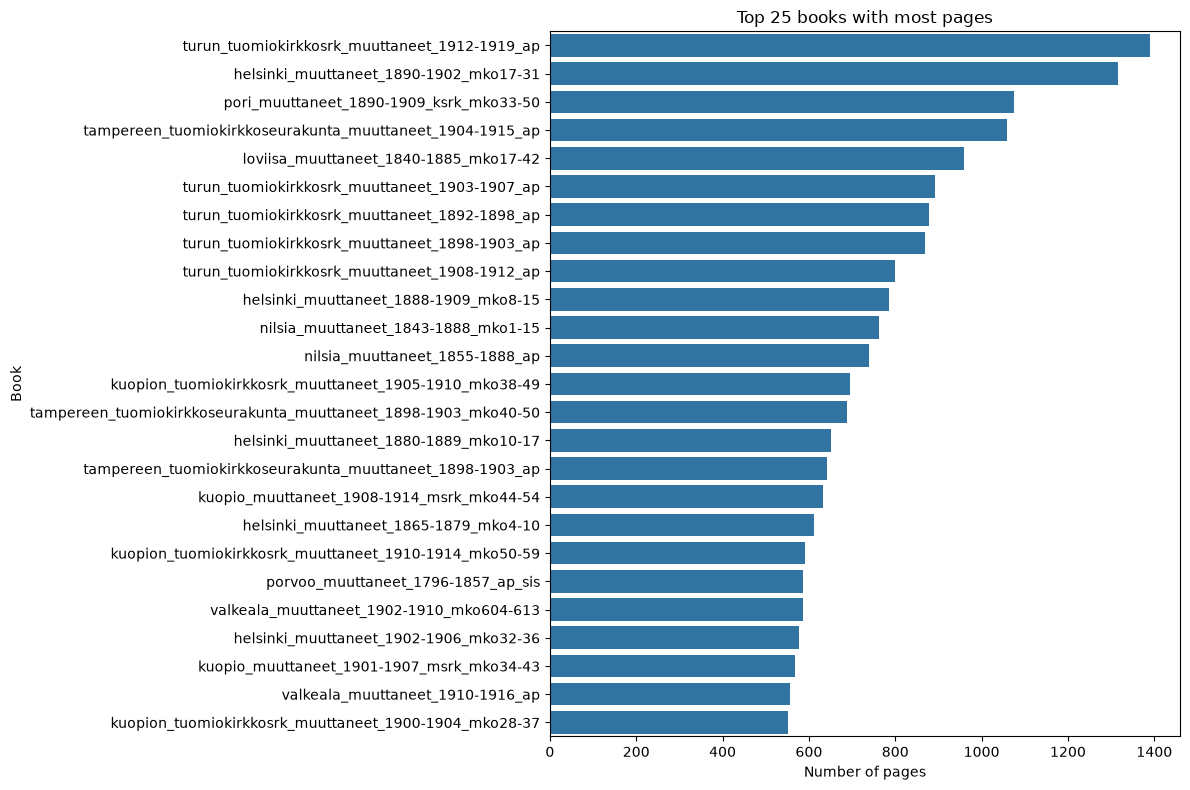

In [5]:
plt.figure(figsize=(12, 8))
sns.barplot(
    data=book_pages_df.head(25),
    x="page_count",
    y="book",
)
plt.title("Top 25 books with most pages")
plt.xlabel("Number of pages")
plt.ylabel("Book")
plt.tight_layout()
plt.show()

 ### Top 25 books with most duplicate pages/sides

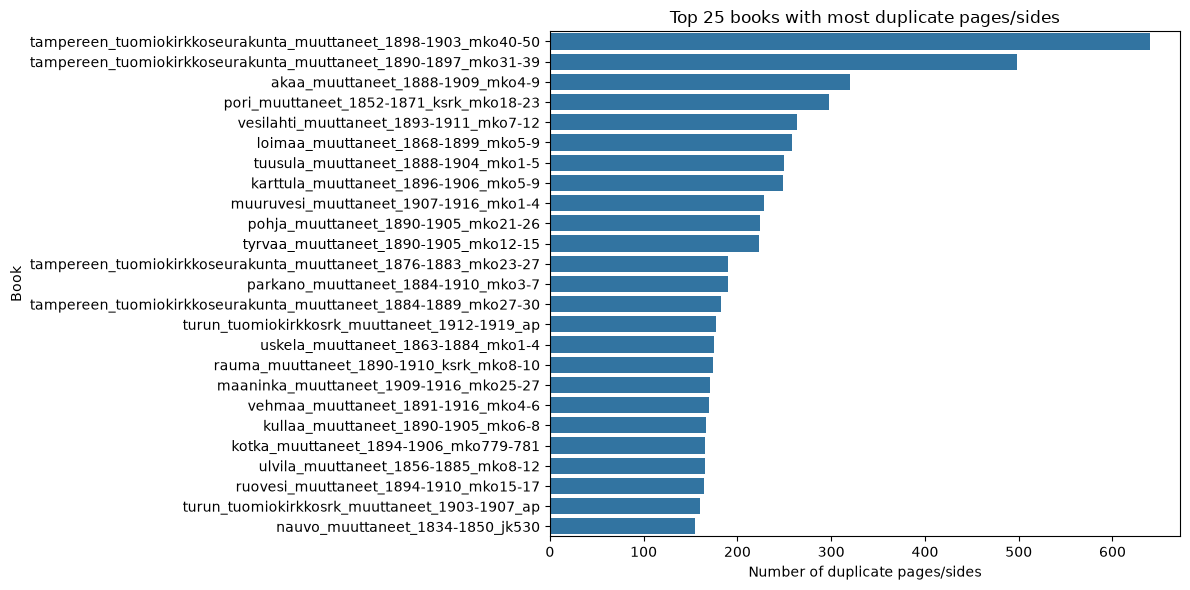

In [6]:
plt.figure(figsize=(12, 6))
sns.barplot(data=duplicate_pages_df.head(25), x="duplicate_count", y="book")
plt.title("Top 25 books with most duplicate pages/sides")
plt.xlabel("Number of duplicate pages/sides")
plt.ylabel("Book")
plt.tight_layout()
plt.show()

 ## Parishes

 ### Top 25 parishes with most events

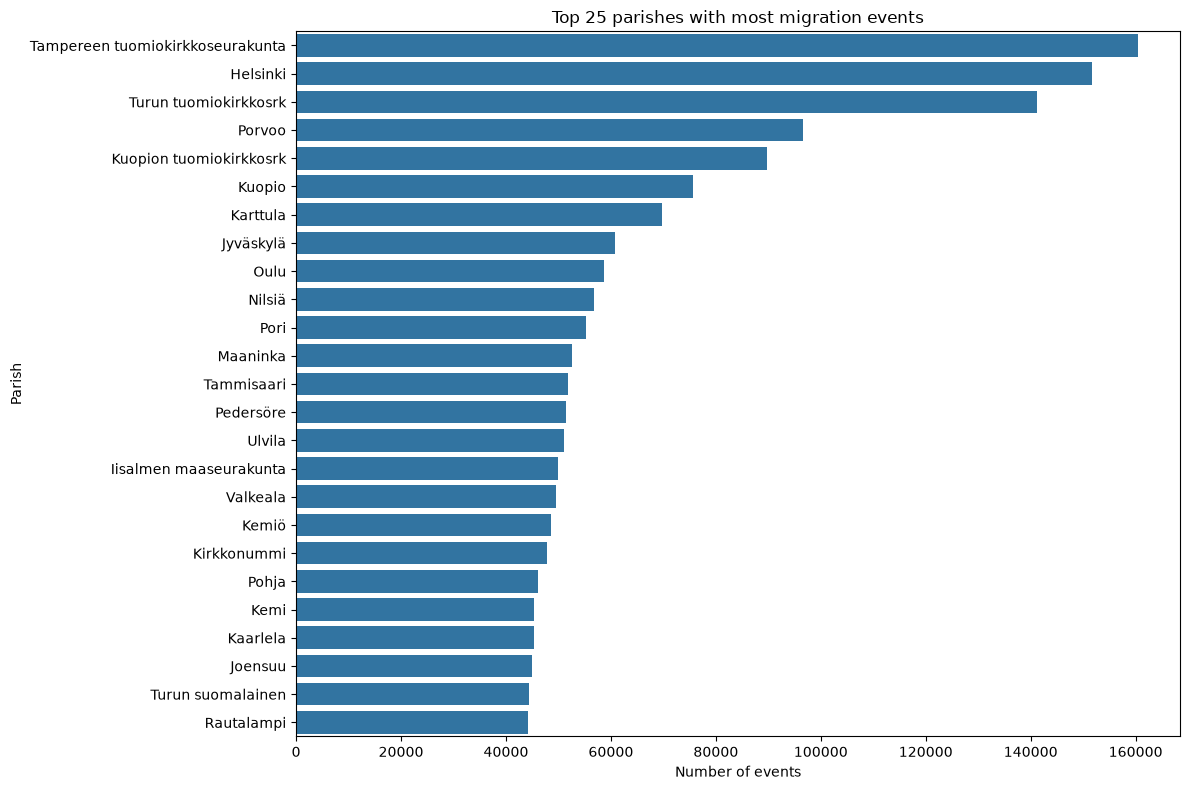

In [7]:
plt.figure(figsize=(12, 8))
sns.barplot(
    data=parish_event_counts.head(25),
    x="event_count",
    y="parish_name",
)
plt.title("Top 25 parishes with most migration events")
plt.xlabel("Number of events")
plt.ylabel("Parish")
plt.tight_layout()
plt.show()

 ### Top 25 parishes with most pages

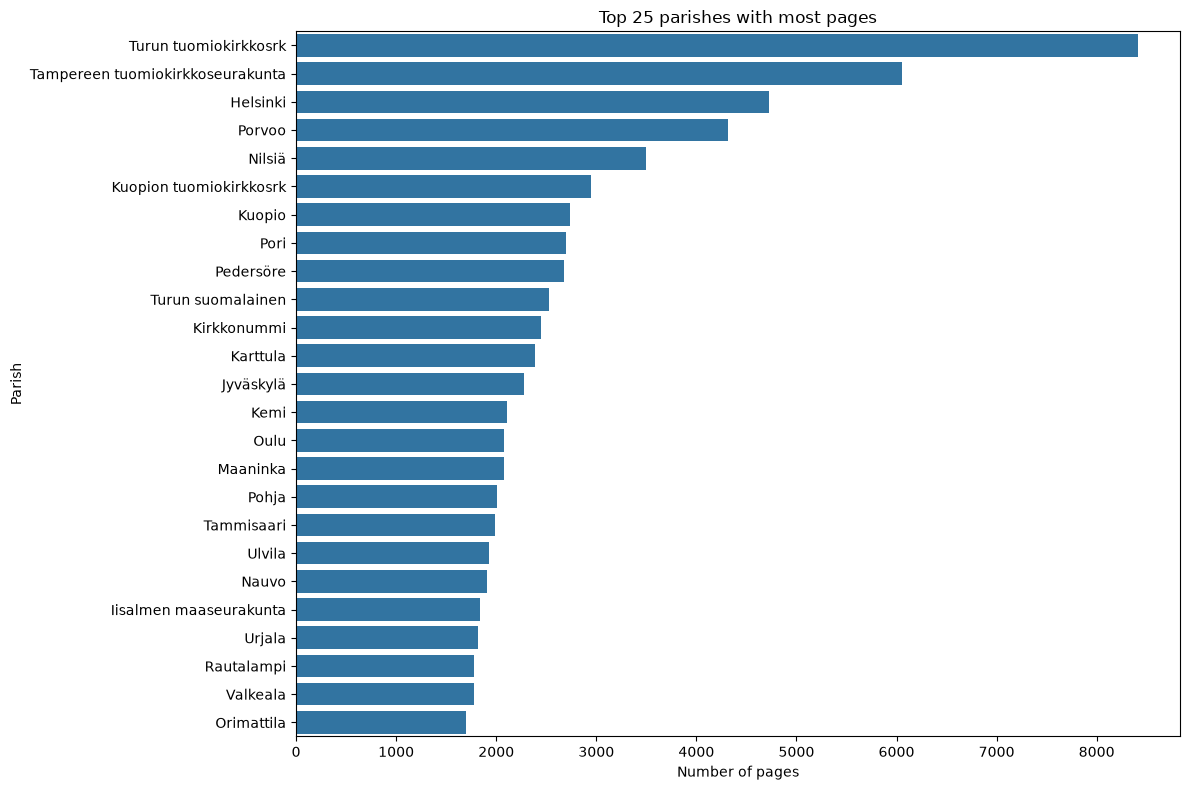

In [8]:
plt.figure(figsize=(12, 8))
sns.barplot(
    data=pages_per_parish_df.head(25),
    x="page_count",
    y="parish_name",
)
plt.title("Top 25 parishes with most pages")
plt.xlabel("Number of pages")
plt.ylabel("Parish")
plt.tight_layout()
plt.show()

 ### Top 25 parishes with most duplicate pages

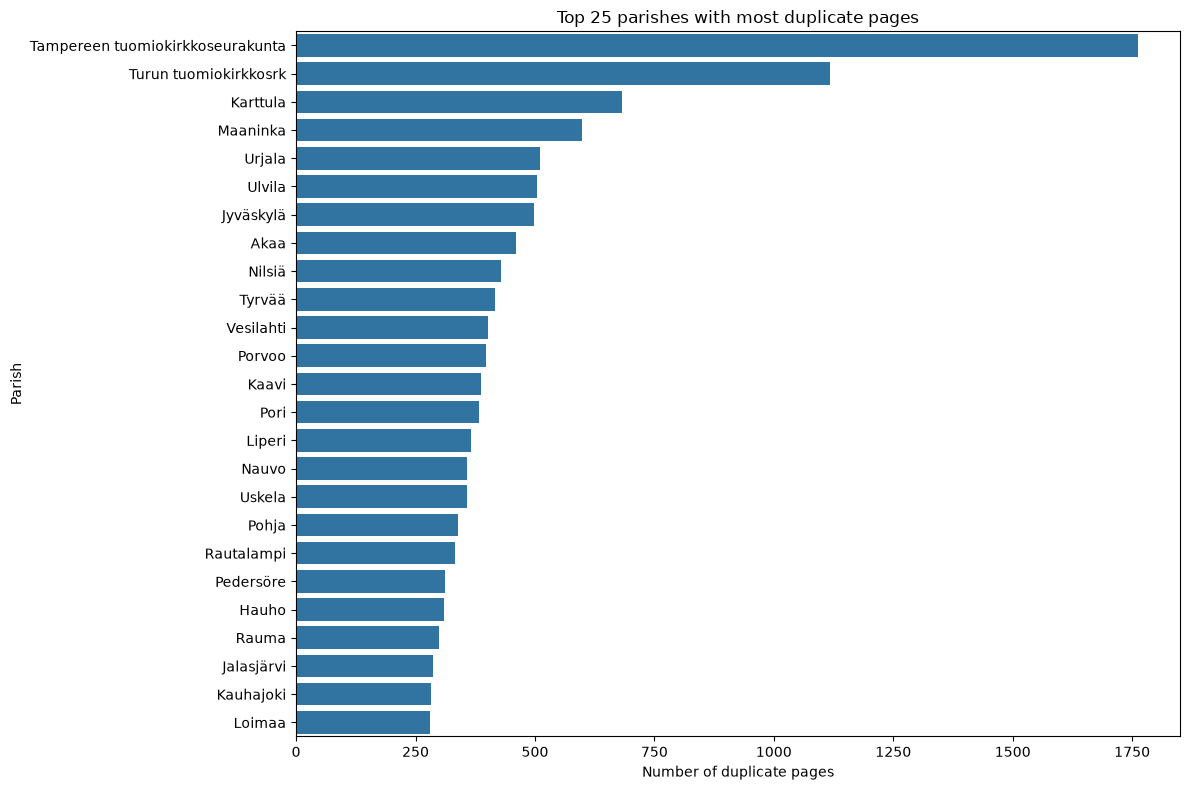

In [9]:
plt.figure(figsize=(12, 8))
sns.barplot(
    data=duplicate_pages_per_parish_df.head(25),
    x="duplicate_count",
    y="parish_name",
)
plt.title("Top 25 parishes with most duplicate pages")
plt.xlabel("Number of duplicate pages")
plt.ylabel("Parish")
plt.tight_layout()
plt.show()

 ## Pages and duplicate pages per year-prediction (5-Year Buckets)

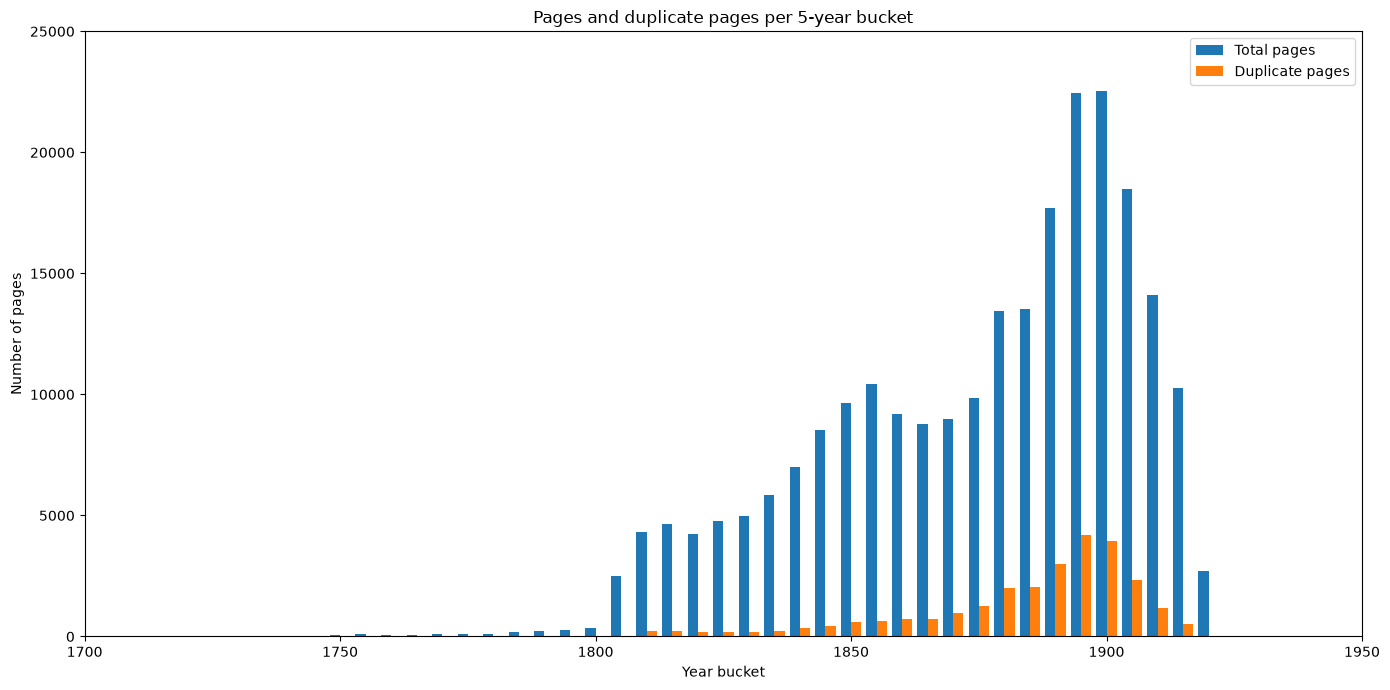

In [10]:
pages_yearly_merged = pages_yearly.merge(
    duplicate_pages_yearly, on="year_bucket", how="left"
).fillna(0)

width = 2.0
plt.figure(figsize=(14, 7))
plt.bar(
    pages_yearly_merged["year_bucket"] - width / 2,
    pages_yearly_merged["total_pages"],
    width=width,
    label="Total pages",
)
plt.bar(
    pages_yearly_merged["year_bucket"] + width / 2,
    pages_yearly_merged["duplicate_pages"],
    width=width,
    label="Duplicate pages",
)
plt.title("Pages and duplicate pages per 5-year bucket")
plt.xlabel("Year bucket")
plt.ylabel("Number of pages")
plt.xlim(1700, 1950)
plt.ylim(0, 25000)
plt.legend()
plt.tight_layout()
plt.show()

 ## Book year coverage, year-prediction mistakes

In [11]:
page_metadata_df = pd.DataFrame.from_records(page_metadata).T
book_zero_year_pages = page_metadata_df[page_metadata_df["year_bucket"] == 0].reset_index()[["book", "index"]].groupby("book").count().reset_index()
book_zero_year_pages = book_zero_year_pages.rename({"index": "zero_year_pages"}, axis="columns")
book_pages_df = book_pages_df.merge(book_zero_year_pages, on="book")

In [12]:
book_year_start_counter: dict[str, int] = {}
book_year_start_counter[record["book"]] = int(record["book_year_start"])

In [13]:
book_pages_df["book_years"] = book_pages_df["book"].str.extract(
    "([0-9]{4})-([0-9]{4})"
).apply(lambda x: list(range(int(x[0]), int(x[1]) + 1)), axis="columns")
book_pages_df["book_year_start"] = book_pages_df["book_years"].map(lambda x: x[0])
book_pages_df["zero_year_ratio"] = (
    book_pages_df["zero_year_pages"] / book_pages_df["page_count"]
)

year_bins = list(range(1700, 1981, 5))
book_pages_df["year_bucket"] = pd.cut(
    book_pages_df["book_year_start"],
    bins=year_bins,
    labels=year_bins[:-1],
)
bucketed = (
    book_pages_df.groupby("year_bucket", observed=True)
    .apply(
        lambda g: pd.Series({
            "weighted_zero_ratio": (
                (g["zero_year_ratio"] * g["page_count"]).sum()
                / g["page_count"].sum()
            ),
            "zero_ratio": (
                g["zero_year_ratio"].mean()
            ),
            "total_pages": g["page_count"].sum(),
            "book_count": len(g),
        })
    )
    .reset_index()
)

 ### Years covered by books

(0.0, 35000.0)

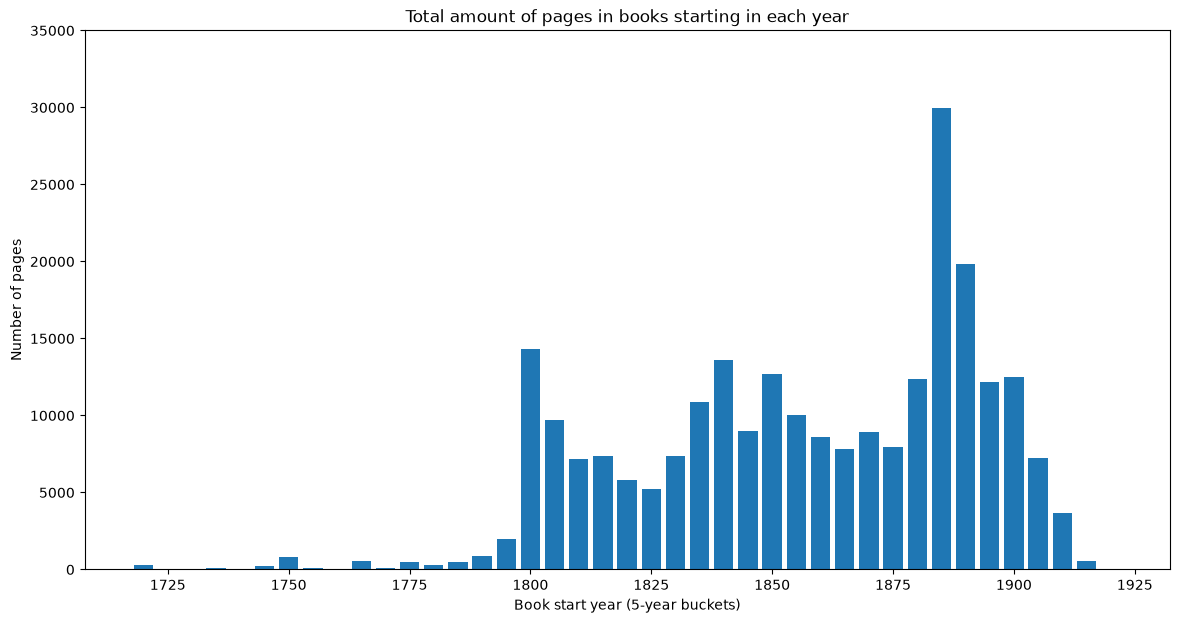

In [14]:
fig, ax = plt.subplots(figsize=(14, 7))
ax.bar(
    bucketed["year_bucket"].astype(int),
    bucketed["total_pages"],
    label="Total pages",
    width=4.0
)

ax.set_xlabel("Book start year (5-year buckets)")
ax.set_ylabel("Number of pages")
ax.set_title("Total amount of pages in books starting in each year")
ax.set_ylim((0, 35000))

 ### Year-prediction mistakes

(0.0, 1.0)

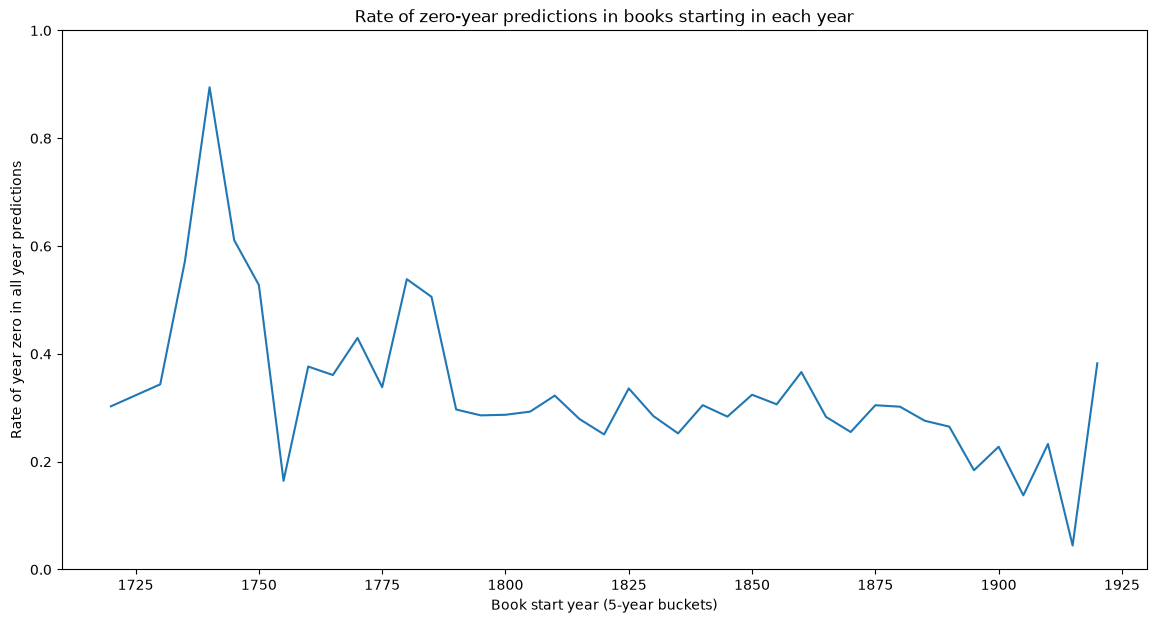

In [15]:
fig, ax = plt.subplots(figsize=(14, 7))

ax.plot(
    bucketed["year_bucket"].astype(int),
    bucketed["zero_ratio"],
    label="Zero-year ratio",
)

ax.set_xlabel("Book start year (5-year buckets)")
ax.set_ylabel("Rate of year zero in all year predictions")
ax.set_title("Rate of zero-year predictions in books starting in each year")
ax.set_ylim((0, 1))

 ## Pages per direction and duplicate pages per direction

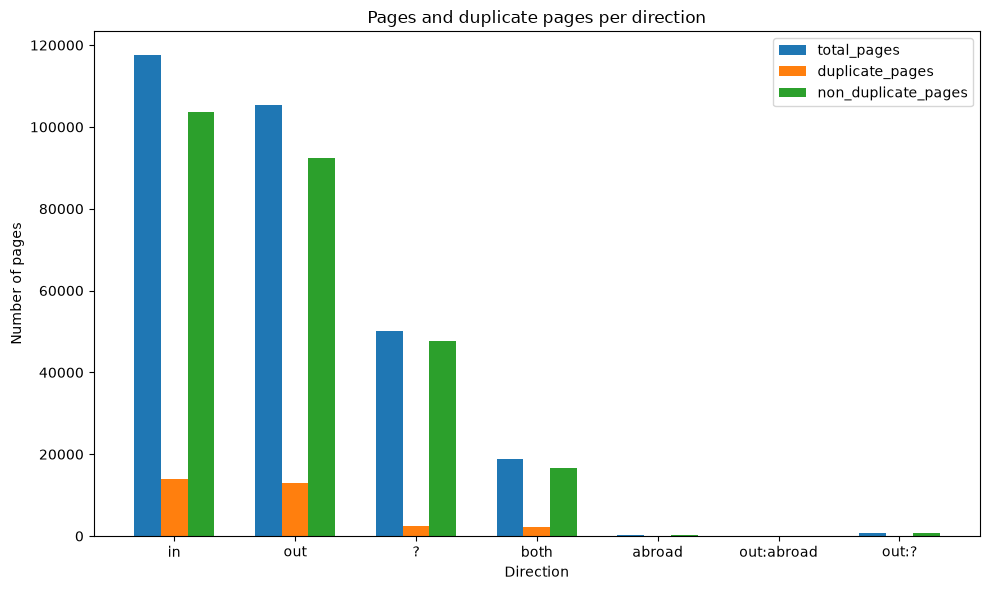

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.grouped_bar(
    direction_data.set_index("direction"), 
)
plt.title("Pages and duplicate pages per direction")
plt.xlabel("Direction")
plt.ylabel("Number of pages")
plt.legend()
plt.tight_layout()
plt.show()

 ## Top 25 most common toponyms

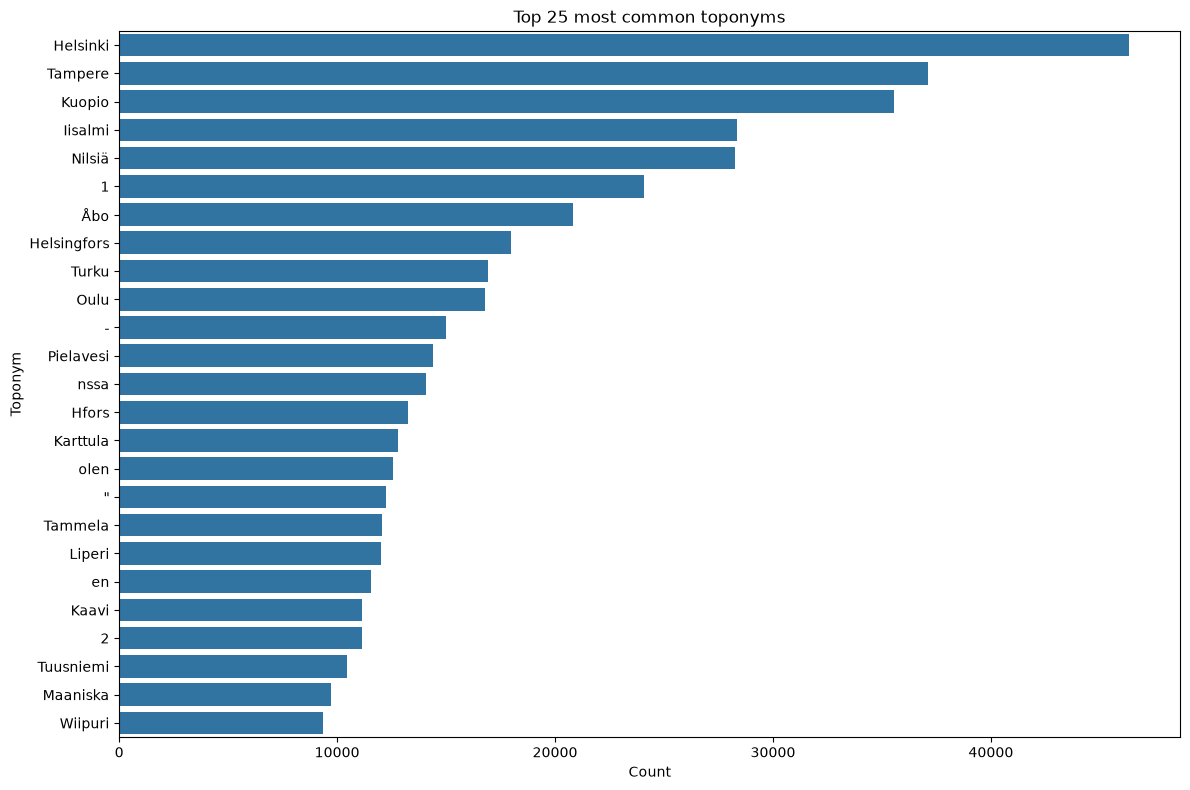

In [17]:
plt.figure(figsize=(12, 8))
sns.barplot(data=toponym_df, x="count", y="toponym")
plt.title("Top 25 most common toponyms")
plt.xlabel("Count")
plt.ylabel("Toponym")
plt.tight_layout()
plt.show()